In [1]:
import os
import pynapple as nap
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [ ]:
# 20231104 is day 2 and consisted of short blocks (20 exposure blocks x 25 sequences with 24% deviant rate, followed by 10 exposure blocks x 25 sequences with 0% deviant rate)

data_day2_path = "../../../Recordings/Silas/Data/20231104"
derivatives_path = "../../derivatives"

data_day2 = nap.EphysReader(f"{data_day2_path}/SeqPre_110423_a001.nev")  # pynapple can load nev files
behav_data_day2_matlab = scipy.io.loadmat(f"{data_day2_path}/Silas_231104_00_bhv/Silas_231104_00_bhv.mat")  # mat73 does not work on this matlab version file

In [ ]:
print(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0].dtype.names)
assert np.all(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0]['blockId'][0] == np.concatenate([np.tile(np.repeat([1, 2], 100), 10), np.zeros(1000, dtype=int)]))  # double-check that the blockID = contextID = context label for each of the 3000 trials is as expected

behav_data_day2 = behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0][['blockId', 'seq', 'imgId', 'imgTime']]
print(behav_data_day2['seq'][0][0].shape)
print(behav_data_day2['seq'][0][0])

('numBlockPair', 'totalSeqsPerBlock', 'swapRepeats', 'swapRate', 'blockNum', 'cur_blockNum', 'blockId', 'cur_blockId', 'blockStartTime', 'blockEndTime', 'imgNum', 'cur_imgNum', 'imgId', 'imgTime', 'numTestBlocks', 'numTestSeqs', 'initialStartTime', 'seqStartTime', 'seqEndTime', 'seq', 'RewardSt', 'RewardEd', 'Eye')
(1, 25)
[[array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dty

In [ ]:
# import mat73
# tmp = mat73.loadmat(f"{data_day2_path}/SeqPre_110423_a001.mat")
# print(tmp['NEV'])

In [ ]:
data_day2

SeqPre_110423_a001
┍━━━━━━━━━━━━━━━━━━━━━━┯━━━━━━━━━━┑
│ Key                  │ Type     │
┝━━━━━━━━━━━━━━━━━━━━━━┿━━━━━━━━━━┥
│ 0:nsx3               │ TsdFrame │
│ 1:nsx4               │ TsdFrame │
│ 2:nsx6               │ TsdFrame │
│ TsGroup              │ TsGroup  │
│ 0:digital_input_port │ Ts       │
│ 1:serial_input_port  │ Ts       │
│ 2:comments           │ Ts       │
┕━━━━━━━━━━━━━━━━━━━━━━┷━━━━━━━━━━┙

In [ ]:
lfp = data_day2['0:nsx3']
spikes = data_day2['TsGroup']

  index    start    end
      0       35     40
shape: (1, 2), time unit: sec.


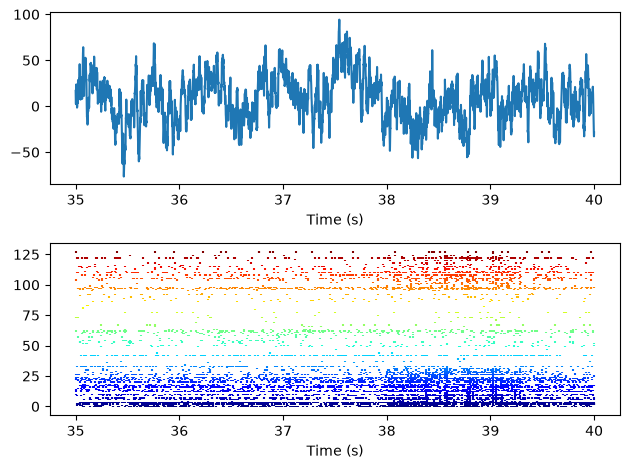

In [13]:
start, end = lfp.t[70000], lfp.t[80000]
win = nap.IntervalSet(start=start, end=end)
print(win)

lfp_win = lfp.get(start, end)
spikes_win = spikes.restrict(win)

fig = plt.figure()
ax1 = fig.add_subplot(2, 1, 1)
ax2 = fig.add_subplot(2, 1, 2)
ax1.plot(lfp_win.t, lfp_win.d[:,42])
ax1.set_xlabel("Time (s)")
colors = plt.cm.jet(np.linspace(0, 1, len(spikes)))
ax2.eventplot([spikes_win[i].t for i in spikes.keys()], colors=colors)
ax2.set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [ ]:
timing = behav_data_day2['imgTime'][0]
timing[-1] - timing[0]

np.float64(4160.83067898103)

In [20]:
spikes.time_support

  index    start     end
      0        0  5390.9
shape: (1, 2), time unit: sec.